# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

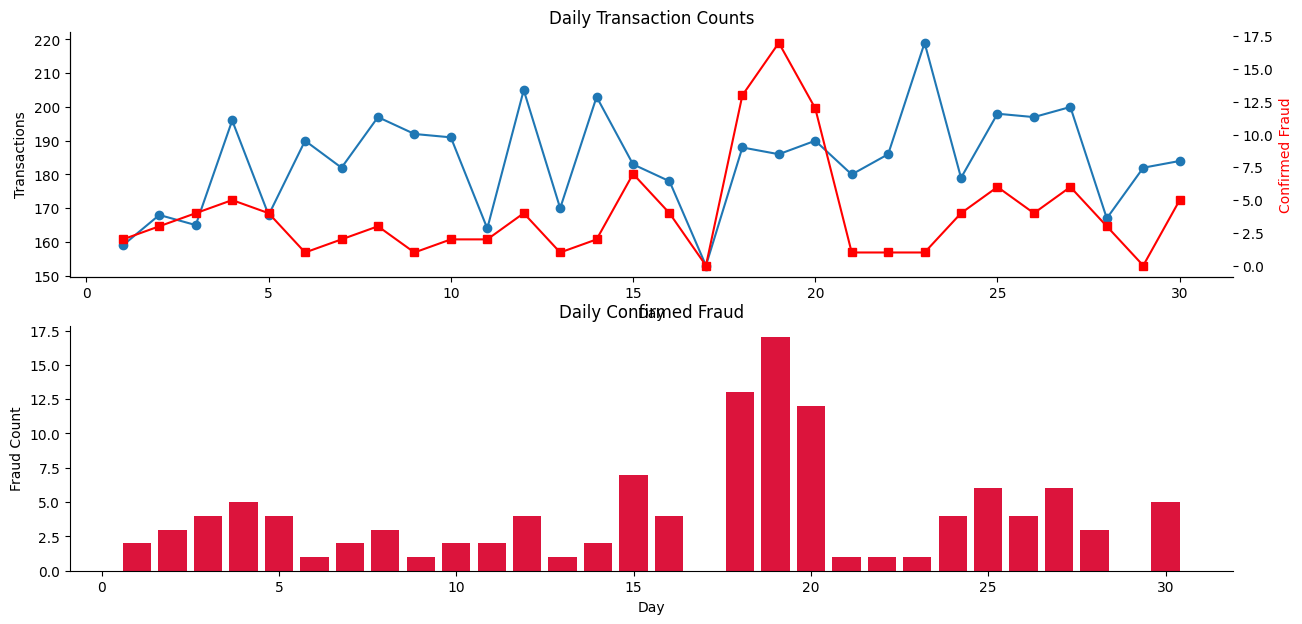

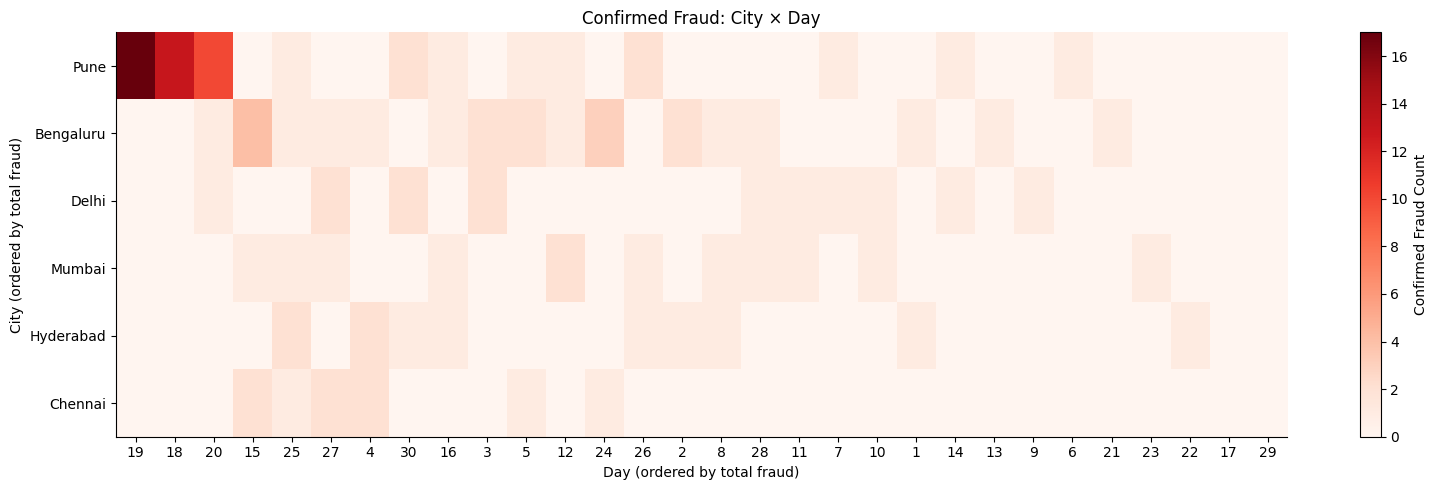

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2
Name: is_fraud, dtype: int64


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(
    transactions=("txn_id", "size"),
    fraud=("is_fraud", "sum")
)

axes[0].plot(daily.index, daily["transactions"], marker="o")
axes[0].set_title("Daily Transaction Counts")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Transactions")

ax2 = axes[0].twinx()
ax2.plot(daily.index, daily["fraud"], color="red", marker="s")
ax2.set_ylabel("Confirmed Fraud", color="red")

axes[1].bar(daily.index, daily["fraud"], color="crimson")
axes[1].set_title("Daily Confirmed Fraud")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Fraud Count")


# TODO 2
heat = tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

fig2, ax_heat = plt.subplots(figsize=(16, 5))
im = ax_heat.imshow(heat, aspect="auto", cmap="Reds", interpolation="nearest")
ax_heat.set_title("Confirmed Fraud: City × Day")
ax_heat.set_xlabel("Day (ordered by total fraud)")
ax_heat.set_ylabel("City (ordered by total fraud)")
ax_heat.set_xticks(range(len(heat.columns)))
ax_heat.set_xticklabels(heat.columns)
ax_heat.set_yticks(range(len(heat.index)))
ax_heat.set_yticklabels(heat.index)
fig2.colorbar(im, ax=ax_heat, label="Confirmed Fraud Count")

plt.tight_layout(); plt.show()

# TODO 3
top_cells = (
    tx.groupby(["city", "day"])["is_fraud"]
    .sum()
    .sort_values(ascending=False)
)

print("Top city-day cells by confirmed fraud:")
print(top_cells.head(10))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ | With 17 cases on day 19, 13 on day 18, and 10 on day 20, the overview revealed a concentration of confirmed fraud in Pune on days 18-20. This geographical and temporal concentration would not be as evident in an alert list arranged by detector score. The **overview first** lecture concept is backed by a reordered matrix that facilitates the identification of high-fraud city-day combinations.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

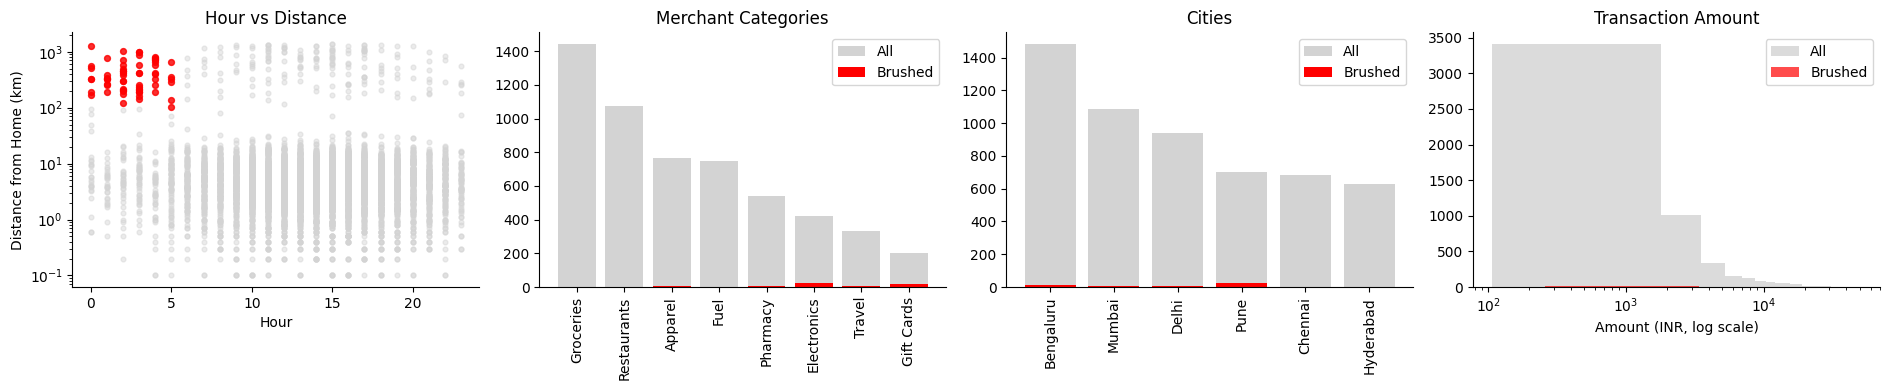

Number brushed: 61
Fraud rate inside brush: 0.8689
Overall fraud rate: 0.0217
Share of all fraud captured: 0.4417


In [4]:
# TODO 1
brush = (tx["night"]) & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
# (a) Hour vs. distance scatter
axes[0].scatter(
    tx["hour"], tx["distance_from_home_km"],
    color="lightgrey", alpha=0.45, s=12
)
axes[0].scatter(
    tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
    color="red", alpha=0.8, s=18
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from Home (km)")
axes[0].set_title("Hour vs Distance")

# (b) Merchant category counts
categories = tx["merchant_category"].value_counts().index
axes[1].bar(categories, tx["merchant_category"].value_counts(),
            color="lightgrey", label="All")
brushed_categories = tx.loc[brush, "merchant_category"].value_counts()
axes[1].bar(brushed_categories.index, brushed_categories.values,
            color="red", label="Brushed")
axes[1].set_title("Merchant Categories")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend()

# (c) City counts
cities = tx["city"].value_counts().index
axes[2].bar(cities, tx["city"].value_counts(),
            color="lightgrey", label="All")
brushed_cities = tx.loc[brush, "city"].value_counts()
axes[2].bar(brushed_cities.index, brushed_cities.values,
            color="red", label="Brushed")
axes[2].set_title("Cities")
axes[2].tick_params(axis="x", rotation=90)
axes[2].legend()

# (d) Amount histogram
axes[3].hist(tx["amount_inr"], bins=30, color="lightgrey",
             alpha=0.8, label="All")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=30, color="red",
             alpha=0.7, label="Brushed")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_title("Transaction Amount")
axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3
brushed_count = int(brush.sum())
brushed_fraud = int(tx.loc[brush, "is_fraud"].sum())
overall_fraud = int(tx["is_fraud"].sum())

print("Number brushed:", brushed_count)
print("Fraud rate inside brush:", round(brushed_fraud / brushed_count, 4))
print("Overall fraud rate:", round(tx["is_fraud"].mean(), 4))
print("Share of all fraud captured:", round(brushed_fraud / overall_fraud, 4))

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ | The brush identified 61 transactions, 53 of which were verified to be fraudulent, yielding an 86.89% fraud rate. Nevertheless, only 44.17% of all confirmed fraud cases (53 out of 120) were captured, leaving 55.83% of fraud unaccounted for. Consequently, the nighttime, far-from-home rule should not be the only one used by investigators. The hour-versus-distance scatter plot illustrates the correlation between transaction time and distance, and the linked city view aids in determining the location of the remaining fraud.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [5]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []

for _ in range(5):
    start = time.perf_counter()
    mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
    elapsed = time.perf_counter() - start
    times.append(elapsed)
best_s = min(times)

# TODO 2
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - (0.1 / t_50m)) * 100)


print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 3.1 ms -> 0.0031 us/row -> max 32,197,214 rows in 0.1 s
50M rows -> 0.16 s; must skip 35.6% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ | Sampling is a reduce technique that evaluates a representative subset of transactions rather than all 50 million rows. This can help keep interactions within the 0.1-second latency budget and minimize computation. However, the analyst might miss uncommon patterns and infrequent fraud cases that are not included in the sample, which could lower the efficacy of fraud detection.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Capacity-constrained choice:
threshold      0.800000
alerts       144.000000
TP            84.000000
FP            60.000000
FN            36.000000
precision      0.583333
recall         0.700000
F1             0.636364
Name: 15, dtype: float64

Best-F1 choice:
threshold      0.850000
alerts       128.000000
TP            79.000000
FP            49.000000
FN            41.000000
precision      0.617188
recall         0.658333
F1             0.637097
Name: 16, dtype: float64


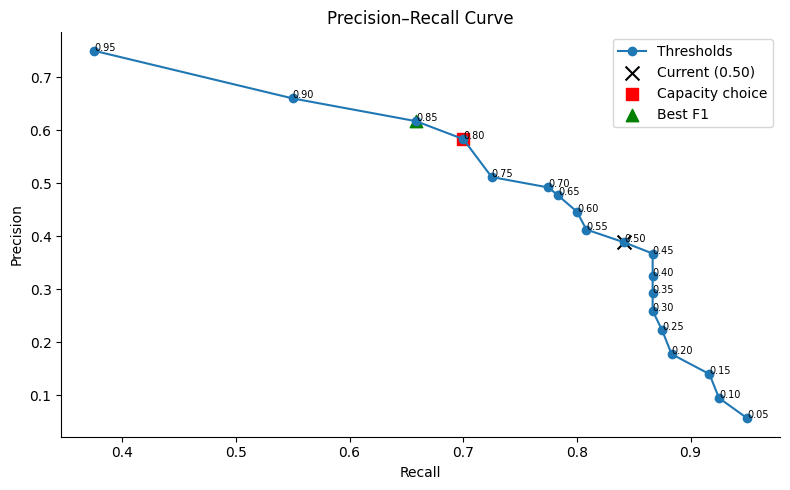

Recommendation: use threshold 0.80 to meet the 150-alert capacity, producing 144 alerts with 58.3% precision and 70.0% recall. The best-F1 threshold is 0.85; the Head of Fraud Ops should approve the final trade-off.


In [6]:
rows = []
# TODO 1
for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = tx["detector_score"] >= threshold
    actual = tx["is_fraud"] == 1

    TP = int((predicted & actual).sum())
    FP = int((predicted & ~actual).sum())
    FN = int((~predicted & actual).sum())
    alerts = int(predicted.sum())

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    F1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    rows.append({
        "threshold": round(threshold, 2),
        "alerts": alerts,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": F1
    })


pr = pd.DataFrame(rows)

# TODO 2
capacity_options = pr[pr["alerts"] <= 150]
capacity_choice = capacity_options.sort_values(
    ["recall", "threshold"],
    ascending=[False, True]
).iloc[0]
best_f1 = pr.loc[pr["F1"].idxmax()]
print("Capacity-constrained choice:")
print(capacity_choice)
print("\nBest-F1 choice:")
print(best_f1)

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o",
        label="Thresholds")

for _, row in pr.iterrows():
    ax.annotate(
        f'{row["threshold"]:.2f}',
        (row["recall"], row["precision"]),
        fontsize=7
    )

current = pr.loc[pr["threshold"] == 0.50].iloc[0]

ax.scatter(current["recall"], current["precision"],
           color="black", marker="x", s=100, label="Current (0.50)")
ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
           color="red", marker="s", s=80, label="Capacity choice")
ax.scatter(best_f1["recall"], best_f1["precision"],
           color="green", marker="^", s=80, label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(
    f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
    f"to meet the 150-alert capacity, producing "
    f"{int(capacity_choice['alerts'])} alerts with "
    f"{capacity_choice['precision']:.1%} precision and "
    f"{capacity_choice['recall']:.1%} recall. "
    f"The best-F1 threshold is {best_f1['threshold']:.2f}; "
    "the Head of Fraud Ops should approve the final trade-off."
)


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ | The final threshold decision should be made by the Head of Fraud Operations, who should base it on operational requirements and model metrics. Within the monthly capacity of 150, a threshold of 0.80 produces 144 alerts with 58.33% precision and 70.00% recall, identifying 84 of the 120 confirmed fraud cases. Although the recall drops to 65.83%, the best-F1 threshold of 0.85 yields a marginally higher F1 score of 0.6371 compared to 0.6364 at 0.80. Because the model cannot decide on its own how to balance missed fraud, false alerts, investigation capacity, and business risk, visual analytics keeps a human in the loop.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    hover_data=[
        "txn_id",
        "customer_id",
        "city",
        "merchant_category",
        "distance_from_home_km",
        "detector_score"
    ],
    log_y=True,
    title="Flagged Transactions: Interactive Investigation"
)

fig_scatter.update_layout(dragmode="select")
fig_scatter.show()


# TODO 2
sunburst_data = tx.groupby(
    ["city", "merchant_category"],
    as_index=False
).agg(
    transaction_count=("txn_id", "size"),
    fraud_count=("is_fraud", "sum")
)

sunburst_data["fraud_rate"] = (
    sunburst_data["fraud_count"] / sunburst_data["transaction_count"]
)

fig_sunburst = px.sunburst(
    sunburst_data,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Transaction Distribution and Fraud Rate by City and Category",
    hover_data={
        "transaction_count": True,
        "fraud_count": True,
        "fraud_rate": ":.2%"
    }
)

fig_sunburst.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ | When looking into 401 flagged transactions, tooltips become annoying because the investigator has to look at each case separately to find more general patterns, which makes comparisons laborious and slow. This is addressed by the interactive scatter plot, which shows all of the transactions that have been flagged together and offers hover, zooming, and selection options when necessary. This enables investigators to transition from an overall view to individual cases by adhering to the principle of overview first, zoom and filter, then details on demand.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune during days 18–20.
Transactions inside window: 107
Confirmed fraud inside window: 40
Fraud rate inside window: 37.38%
Transactions outside window: 5413
Confirmed fraud outside window: 80
Fraud rate outside window: 1.48%
Chi-square statistic: 619.2941533967205
Chi-square p-value: 1.0648203911801525e-136
Window: 107 transactions, 40 fraud, fraud rate = 37.38%
Pune, other days: 593 transactions, 11 fraud, fraud rate = 1.85%
Other cities, same days: 457 transactions, 2 fraud, fraud rate = 0.44%
Rest: 4363 transactions, 67 fraud, fraud rate = 1.54%


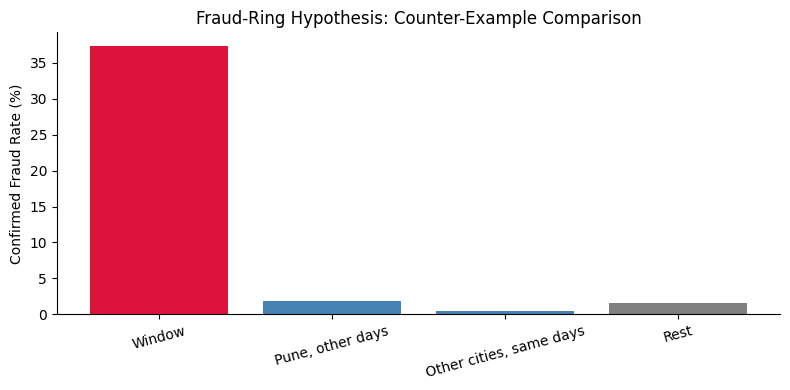

Verdict: strong statistical evidence of fraud concentration in Pune during days 18–20. Investigate the cluster, but the evidence alone does not prove a coordinated fraud ring.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (
    (tx["city"] == "Pune") &
    (tx["day"].between(18, 20))
)

# TODO 2
inside = tx.loc[in_window, "is_fraud"]
outside = tx.loc[~in_window, "is_fraud"]

print("Hypothesis: confirmed fraud is unusually concentrated in Pune "
      "during days 18–20.")
print("Transactions inside window:", len(inside))
print("Confirmed fraud inside window:", int(inside.sum()))
print("Fraud rate inside window:", f"{inside.mean():.2%}")
print("Transactions outside window:", len(outside))
print("Confirmed fraud outside window:", int(outside.sum()))
print("Fraud rate outside window:", f"{outside.mean():.2%}")

contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("Chi-square p-value:", p_value)

# TODO 3
same_city_other_days = (
    (tx["city"] == "Pune") &
    ~tx["day"].between(18, 20)
)

other_cities_same_days = (
    (tx["city"] != "Pune") &
    tx["day"].between(18, 20)
)

rest = (
    (tx["city"] != "Pune") &
    ~tx["day"].between(18, 20)
)

groups = {
    "Window": in_window,
    "Pune, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest
}

group_rates = {}

for name, mask in groups.items():
    count = int(mask.sum())
    fraud_count = int(tx.loc[mask, "is_fraud"].sum())
    rate = tx.loc[mask, "is_fraud"].mean()
    group_rates[name] = rate

    print(
        f"{name}: {count} transactions, "
        f"{fraud_count} fraud, fraud rate = {rate:.2%}"
    )


# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
names = list(group_rates.keys())
rates = [group_rates[name] * 100 for name in names]

ax.bar(names, rates, color=["crimson", "steelblue",
                            "steelblue", "grey"])
ax.set_ylabel("Confirmed Fraud Rate (%)")
ax.set_title("Fraud-Ring Hypothesis: Counter-Example Comparison")
ax.tick_params(axis="x", rotation=15)

plt.tight_layout(); plt.show()

# TODO 5
if p_value < 0.05 and group_rates["Window"] > max(
    group_rates["Pune, other days"],
    group_rates["Other cities, same days"],
    group_rates["Rest"]
):
    print(
        "Verdict: strong statistical evidence of fraud concentration "
        "in Pune during days 18–20. Investigate the cluster, but the "
        "evidence alone does not prove a coordinated fraud ring."
    )
else:
    print(
        "Verdict: the data does not establish a statistically "
        "significant, uniquely concentrated fraud cluster in the "
        "specified window. Do not conclude that a fraud ring exists."
    )


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ | If its fraud rate were similarly high outside of days 18-20, the comparison with Pune on other days would undermine the hypothesis, indicating a persistent city-specific problem rather than a time-specific cluster. If other cities had similarly high fraud rates during days 18-20, the comparison would undermine the hypothesis and point to a more widespread occurrence that affected several cities. According to the actual output, Pune's fraud rate during the window was 37.38%, while it was 0.44% in other cities and 1.85% in Pune on other days. Although a strong statistical association is indicated by the chi-square p-value of roughly 1.06 x 10⁻¹³⁶, this does not prove that a fraud ring coordinated the transactions.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

PayKart recorded 5,520 transactions and 120 confirmed fraud cases (2.17%) last month. During days 18-20, there was a noticeable concentration of 40 fraud cases in Pune, including 17 cases on day 19. Since it produces 144 alerts within the monthly capacity of 150, achieves 58.33% precision and 70.00% recall, and finds 84 confirmed fraud cases, I suggest a detector threshold of 0.80; the Head of Fraud Ops should approve the final trade-off. The flagged-transaction scatter plot, which supports overview first, selection, and details on demand for examining specific cases and more general patterns, ought to be the first interactive tool. Since the statistical association does not prove the existence of a coordinated fraud ring, more research should be done on the Pune cluster. Finally, introduce an investigator feedback loop by collecting confirmed case outcomes and using those labels to evaluate and retrain the detector for the following month.